# Human Activity Recognition (Smartphone Sensors)

**Dataset:** UCI HAR — 30 volunteers wore a waist-mounted smartphone; its accelerometer and gyroscope recorded them doing 6 activities (walking, walking upstairs, walking downstairs, sitting, standing, laying). The published dataset already converts the signals into **561 engineered features** per window, with a fixed train/test split by volunteer — so the model is tested on people it never saw.

In [1]:
import io, urllib.request, zipfile
import numpy as np

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

zf = zipfile.ZipFile(io.BytesIO(get('https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip')))
inner = [n for n in zf.namelist() if n.endswith('.zip')][0]
zf2 = zipfile.ZipFile(io.BytesIO(zf.read(inner)))
def rd(suffix):
    n = [x for x in zf2.namelist() if x.endswith(suffix)][0]
    return zf2.read(n)
Xtr = np.loadtxt(io.BytesIO(rd('train/X_train.txt'))); ytr = np.loadtxt(io.BytesIO(rd('train/y_train.txt'))).astype(int)
Xte = np.loadtxt(io.BytesIO(rd('test/X_test.txt'))); yte = np.loadtxt(io.BytesIO(rd('test/y_test.txt'))).astype(int)
ACT = ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']
print('Train:', Xtr.shape, 'Test:', Xte.shape)

Train: (7352, 561) Test: (2947, 561)


Accuracy on unseen volunteers: 0.9552
                    precision    recall  f1-score   support

           Walking       0.94      0.99      0.97       496
  Walking Upstairs       0.96      0.95      0.95       471
Walking Downstairs       0.99      0.94      0.96       420
           Sitting       0.97      0.88      0.92       491
          Standing       0.89      0.97      0.93       532
            Laying       1.00      0.99      1.00       537

          accuracy                           0.96      2947
         macro avg       0.96      0.95      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



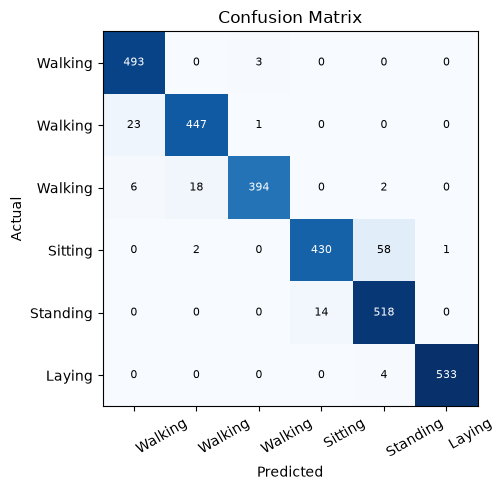

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000).fit(sc.transform(Xtr), ytr)
pred = lr.predict(sc.transform(Xte))
print('Accuracy on unseen volunteers:', round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, target_names=ACT))
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(6), [a.split()[0] for a in ACT], rotation=30, ha='left'); ax.set_yticks(range(6), [a.split()[0] for a in ACT])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix')
for i in range(6):
    for j in range(6):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- With well-engineered sensor features, a plain logistic regression is extremely strong — the features do the heavy lifting.
- The split-by-person design is the honest way to evaluate wearables: random splits would leak each volunteer's gait into both sets.
- Remaining confusions are the physically similar pairs (sitting vs standing).